In [1]:
!pip install tensorflow matplotlib seaborn pandas scikit-learn -q

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import time

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout,
    BatchNormalization, GlobalAveragePooling2D
)

from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [3]:
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

print("Training Dataset:", X_train_full.shape)
print("Testing Dataset:", X_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training Dataset: (60000, 28, 28)
Testing Dataset: (10000, 28, 28)


In [4]:
# Normalize images
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Split training and validation datasets
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=10000,
    random_state=42,
    stratify=y_train_full
)

# Add channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_val = X_val.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (50000, 28, 28, 1)
Validation: (10000, 28, 28, 1)
Testing: (10000, 28, 28, 1)


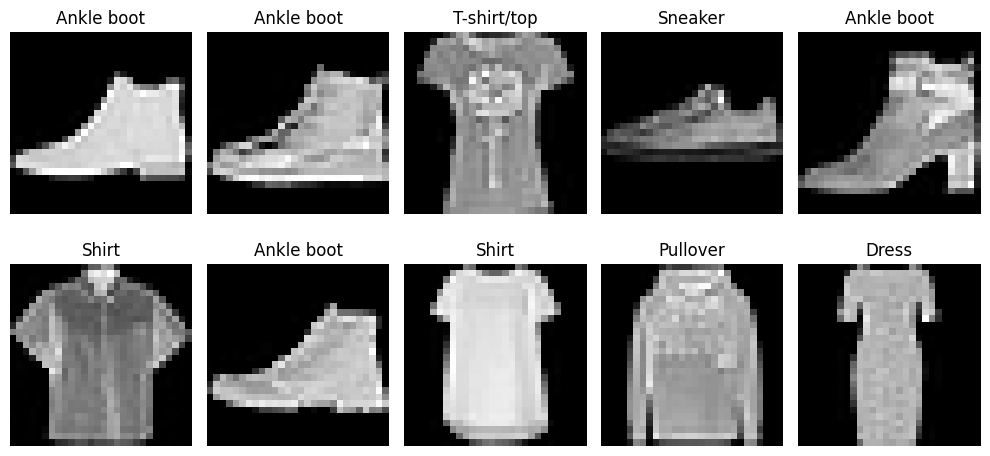

In [5]:
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover',
    'Dress', 'Coat', 'Sandal',
    'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i].squeeze(), cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [6]:
def build_basic_cnn():

    model = Sequential([
        Input(shape=(28, 28, 1)),

        Conv2D(32, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),

        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),

        Flatten(),

        Dense(128, activation='relu'),
        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [7]:
def build_lenet():

    model = Sequential([
        Input(shape=(28, 28, 1)),

        Conv2D(6, (5, 5), activation='tanh'),
        tf.keras.layers.AveragePooling2D((2, 2)),

        Conv2D(16, (5, 5), activation='tanh'),
        tf.keras.layers.AveragePooling2D((2, 2)),

        Flatten(),

        Dense(120, activation='tanh'),
        Dense(84, activation='tanh'),

        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [8]:
def build_deep_cnn():

    model = Sequential([
        Input(shape=(28, 28, 1)),

        # Block 1
        Conv2D(32, (3, 3), padding='same', activation='relu'),
        Conv2D(32, (3, 3), padding='same', activation='relu'),
        MaxPooling2D((2, 2)),

        # Block 2
        Conv2D(64, (3, 3), padding='same', activation='relu'),
        Conv2D(64, (3, 3), padding='same', activation='relu'),
        MaxPooling2D((2, 2)),

        # Block 3
        Conv2D(128, (3, 3), padding='same', activation='relu'),
        MaxPooling2D((2, 2)),

        GlobalAveragePooling2D(),

        Dense(128, activation='relu'),
        Dropout(0.3),

        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [9]:
basic_model = build_basic_cnn()
lenet_model = build_lenet()
deep_model = build_deep_cnn()

print("\nBASIC CNN")
basic_model.summary()

print("\nLENET CNN")
lenet_model.summary()

print("\nDEEP CNN")
deep_model.summary()


BASIC CNN


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 156,650 (611.91 KB)

 Trainable params: 156,650 (611.91 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
models = {
    "Basic CNN": build_basic_cnn(),
    "LeNet-5": build_lenet(),
    "Deep CNN": build_deep_cnn()
}

histories = {}
training_times = {}
results = {}

for name, model in models.items():

    print("\n" + "=" * 50)
    print("Training:", name)
    print("=" * 50)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    # Start timer
    start_time = time.time()

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=128,
        verbose=1
    )

    # Calculate training time
    training_time = time.time() - start_time

    # Evaluate test dataset
    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    histories[name] = history
    training_times[name] = training_time

    results[name] = {
        "Training Accuracy": history.history['accuracy'][-1] * 100,
        "Validation Accuracy": history.history['val_accuracy'][-1] * 100,
        "Test Accuracy": test_accuracy * 100,
        "Training Loss": history.history['loss'][-1],
        "Test Loss": test_loss,
        "Training Time": training_time,
        "Parameters": model.count_params()
    }

    print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
    print("Training Time:", round(training_time, 2), "seconds")


Training: Basic CNN
Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 19s 22ms/step - accuracy: 0.7937 - loss: 0.5738 - val_accuracy: 0.8660 - val_loss: 0.3792
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8678 - loss: 0.3674 - val_accuracy: 0.8840 - val_loss: 0.3216
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8853 - loss: 0.3154 - val_accuracy: 0.8960 - val_loss: 0.2916
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8974 - loss: 0.2827 - val_accuracy: 0.9023 - val_loss: 0.2761
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9064 - loss: 0.2588 - val_accuracy: 0.9050 - val_loss: 0.2662
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9140 - loss: 0.2386 - val_accuracy: 0.9053 - val_loss: 0.2628
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9211 - loss: 0.2203 - val_accuracy: 0.9086 - val_loss: 0.2586
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9273 - loss: 0.

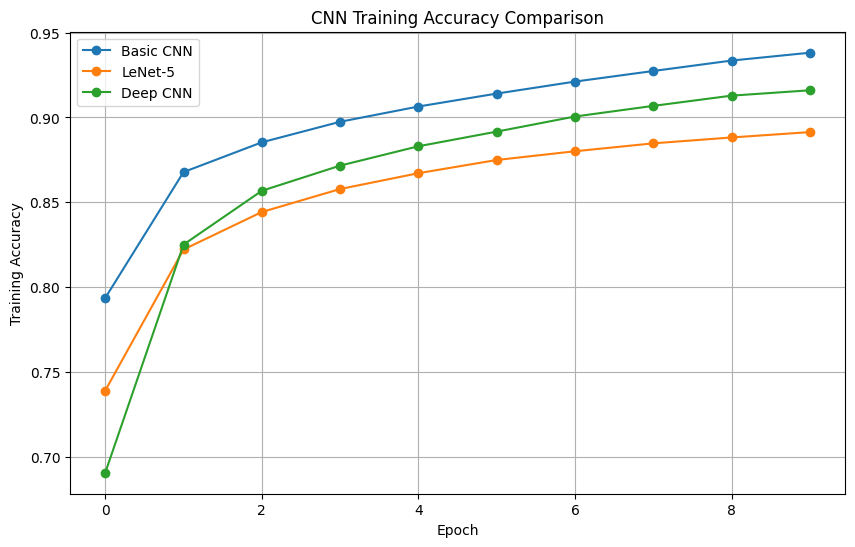

In [11]:
plt.figure(figsize=(10, 6))

for name, history in histories.items():

    plt.plot(
        history.history['accuracy'],
        marker='o',
        label=name
    )

plt.title("CNN Training Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")

plt.legend()
plt.grid(True)
plt.show()

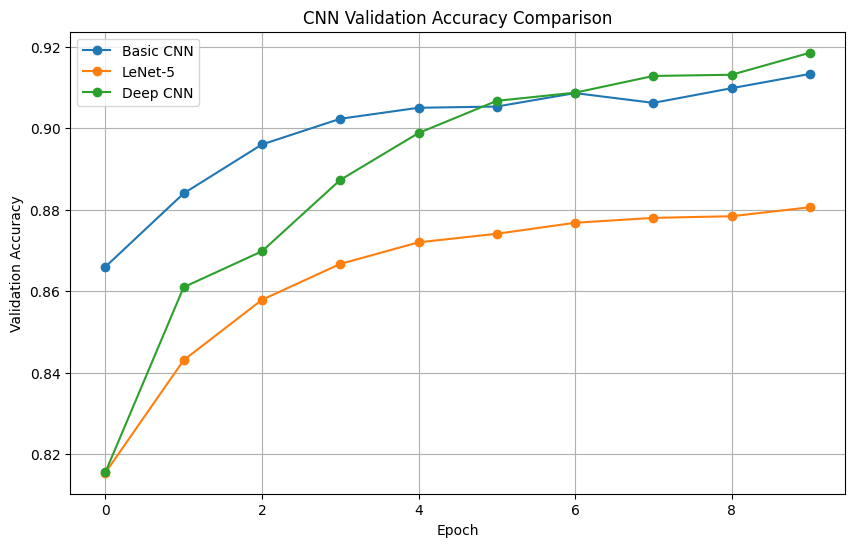

In [12]:
plt.figure(figsize=(10, 6))

for name, history in histories.items():

    plt.plot(
        history.history['val_accuracy'],
        marker='o',
        label=name
    )

plt.title("CNN Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

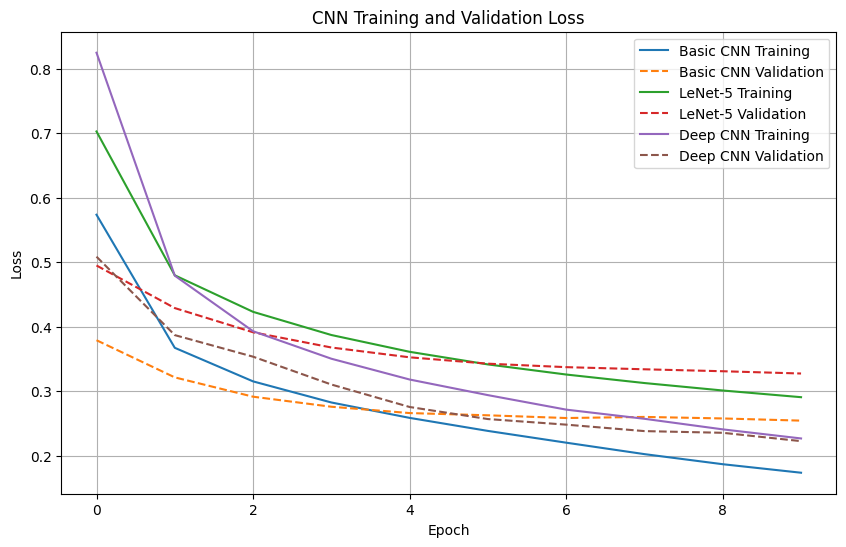

In [13]:
plt.figure(figsize=(10, 6))

for name, history in histories.items():

    plt.plot(
        history.history['loss'],
        label=name + " Training"
    )

    plt.plot(
        history.history['val_loss'],
        linestyle='--',
        label=name + " Validation"
    )

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

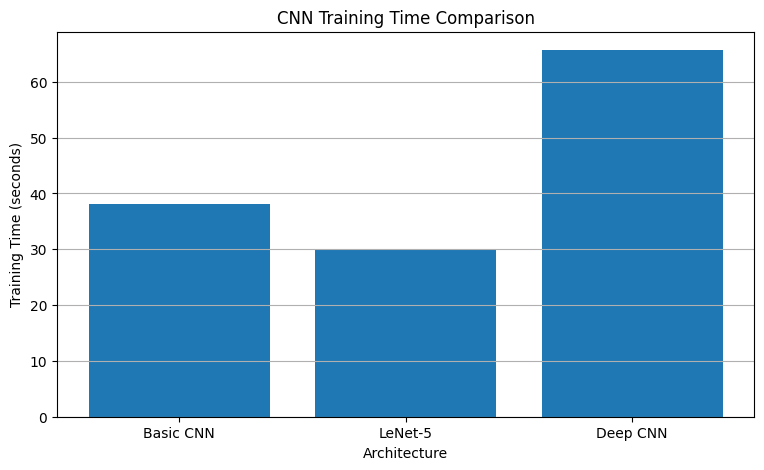

In [14]:
plt.figure(figsize=(9, 5))

plt.bar(
    list(training_times.keys()),
    list(training_times.values())
)

plt.title("CNN Training Time Comparison")
plt.xlabel("Architecture")
plt.ylabel("Training Time (seconds)")

plt.grid(axis='y')
plt.show()

In [15]:
results_df = pd.DataFrame(results).T

print("\nFINAL CNN COMPARISON")
print(results_df.round(4))


FINAL CNN COMPARISON
           Training Accuracy  Validation Accuracy  Test Accuracy  \
Basic CNN             93.810                91.33          90.35   
LeNet-5               89.136                88.06          86.69   
Deep CNN              91.598                91.85          91.03   

           Training Loss  Test Loss  Training Time  Parameters  
Basic CNN         0.1737     0.2761        38.1888    225034.0  
LeNet-5           0.2909     0.3576        30.0859     44426.0  
Deep CNN          0.2269     0.2470        65.6888    156650.0  


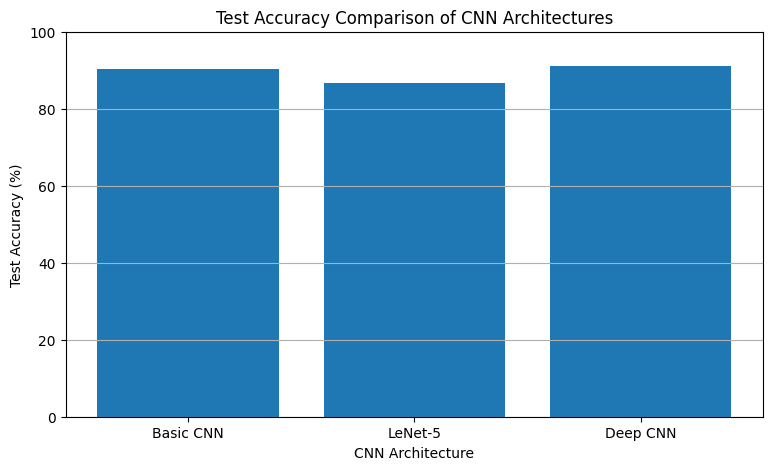

In [16]:
plt.figure(figsize=(9, 5))

plt.bar(
    results_df.index,
    results_df['Test Accuracy']
)

plt.title("Test Accuracy Comparison of CNN Architectures")
plt.xlabel("CNN Architecture")
plt.ylabel("Test Accuracy (%)")

plt.ylim(0, 100)
plt.grid(axis='y')
plt.show()

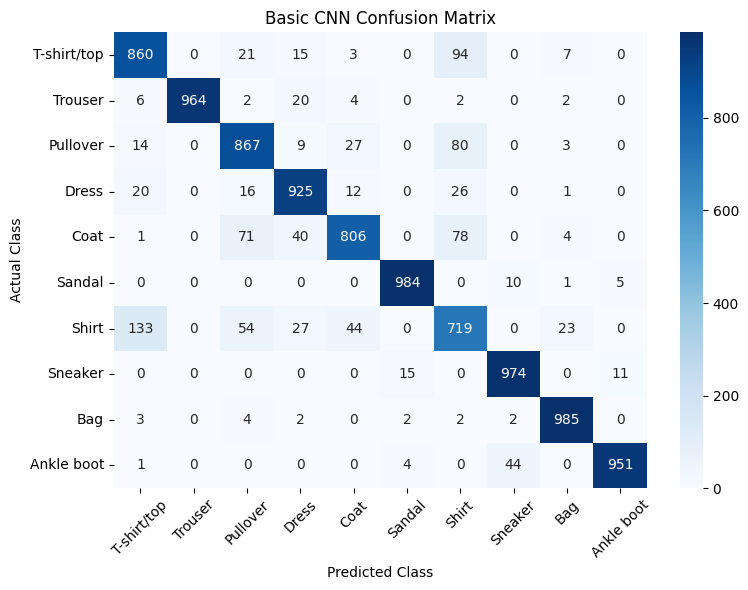

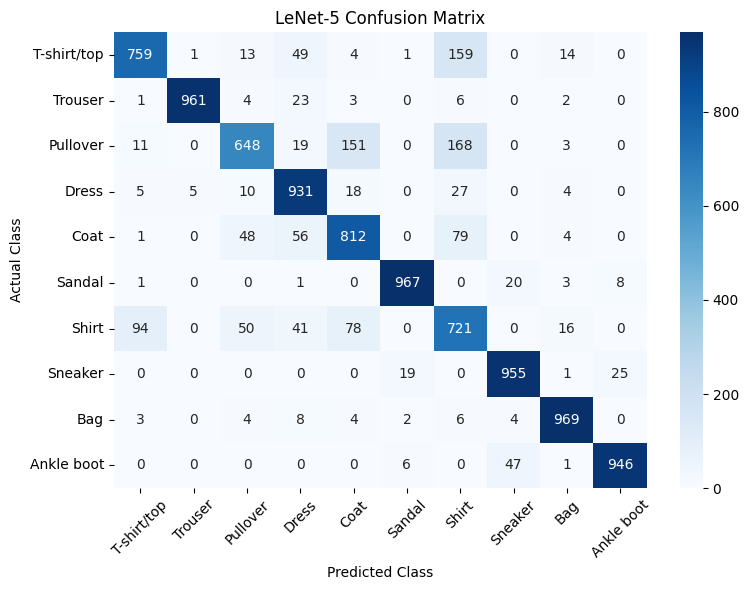

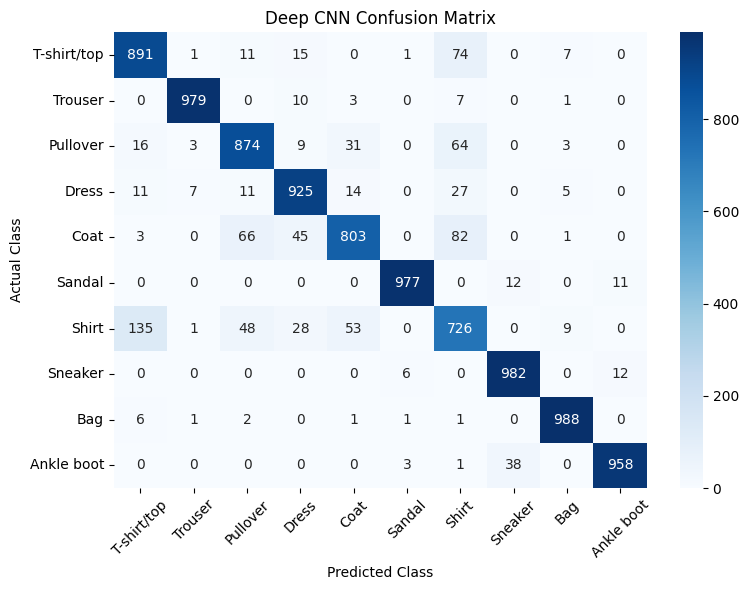

In [17]:
for name, model in models.items():

    predictions = model.predict(X_test, verbose=0)

    y_pred = np.argmax(predictions, axis=1)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.xticks(rotation=45)
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

In [18]:
for name, model in models.items():

    predictions = model.predict(X_test, verbose=0)

    y_pred = np.argmax(predictions, axis=1)

    print("\n", name, "Classification Report")

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=class_names
        )
    )


 Basic CNN Classification Report
              precision    recall  f1-score   support

 T-shirt/top       0.83      0.86      0.84      1000
     Trouser       1.00      0.96      0.98      1000
    Pullover       0.84      0.87      0.85      1000
       Dress       0.89      0.93      0.91      1000
        Coat       0.90      0.81      0.85      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.72      0.72      0.72      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.96      0.98      0.97      1000
  Ankle boot       0.98      0.95      0.97      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000


 LeNet-5 Classification Report
              precision    recall  f1-score   support

 T-shirt/top       0.87      0.76      0.81      1000
     Trouser       0.99      0.96      0.98      1000
    Pullover

In [19]:
best_model = results_df['Test Accuracy'].idxmax()

print("BEST CNN ARCHITECTURE")
print("---------------------")

print("Architecture:", best_model)

print(
    "Test Accuracy:",
    round(results_df.loc[best_model, 'Test Accuracy'], 2),
    "%"
)

print(
    "Training Time:",
    round(results_df.loc[best_model, 'Training Time'], 2),
    "seconds"
)

print(
    "Parameters:",
    int(results_df.loc[best_model, 'Parameters'])
)

BEST CNN ARCHITECTURE
---------------------
Architecture: Deep CNN
Test Accuracy: 91.03 %
Training Time: 65.69 seconds
Parameters: 156650
